In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data Loading & Basic Exploration

1

In [2]:
data = pd.read_csv("crop_yield.csv")

2

In [3]:
data.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


3

In [4]:
data.isnull().sum()

,0
FARM_ID,0
CROP_TYPE,0
YIELD_KG,330
AREA_ACRES,144
HARVEST_DATE,0
DISTRICT,126
SEASON,0
FERTILIZER_USED,318
YIELD_VALUE,0


4

In [5]:
data.dtypes

,0
FARM_ID,object
CROP_TYPE,object
YIELD_KG,float64
AREA_ACRES,float64
HARVEST_DATE,object
DISTRICT,object
SEASON,object
FERTILIZER_USED,object
YIELD_VALUE,int64


5

In [6]:
data.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


6

In [7]:
data.describe(include= "object")

,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


# Data Cleaning


In [8]:
clean_data = data.copy()

7

In [9]:
clean_data = clean_data.dropna(subset=['YIELD_KG'])

8

In [10]:
clean_data['AREA_ACRES'] = clean_data['AREA_ACRES'].fillna(clean_data['AREA_ACRES'].mean())

9

In [11]:
clean_data["DISTRICT"] = clean_data["DISTRICT"].fillna("Unknown")

10

In [12]:
clean_data["FERTILIZER_USED"] = clean_data["FERTILIZER_USED"].fillna("No")

11

In [13]:
clean_data['YIELD_VALUE'] = clean_data['YIELD_VALUE'].fillna(clean_data['YIELD_VALUE'].mean())

12

In [14]:
clean_data['HARVEST_DATE'] = pd.to_datetime(clean_data['HARVEST_DATE'],format='%d/%m/%Y',errors='coerce')

13

In [15]:
clean_data["FARM_ID"] = clean_data["FARM_ID"].str.replace("F", " ", regex=False)
clean_data['FARM_ID'].astype(int)

,FARM_ID
0,1
1,2
2,3
3,4
4,5
...,...
2995,2996
2996,2997
2997,2998
2998,2999


14

In [16]:
clean_data.isnull().sum()

,0
FARM_ID,0
CROP_TYPE,0
YIELD_KG,0
AREA_ACRES,0
HARVEST_DATE,0
DISTRICT,0
SEASON,0
FERTILIZER_USED,0
YIELD_VALUE,0


15

In [17]:
clean_data.dtypes

,0
FARM_ID,object
CROP_TYPE,object
YIELD_KG,float64
AREA_ACRES,float64
HARVEST_DATE,datetime64[ns]
DISTRICT,object
SEASON,object
FERTILIZER_USED,object
YIELD_VALUE,int64


# Data Analysis and Visualization

16

In [18]:
yield_by_crop = clean_data.groupby('CROP_TYPE')["YIELD_KG"].sum()
yield_by_crop

,YIELD_KG
CROP_TYPE,
Maize,1112500.0
Rice,1638000.0
Sugarcane,592000.0
Wheat,2035500.0


17

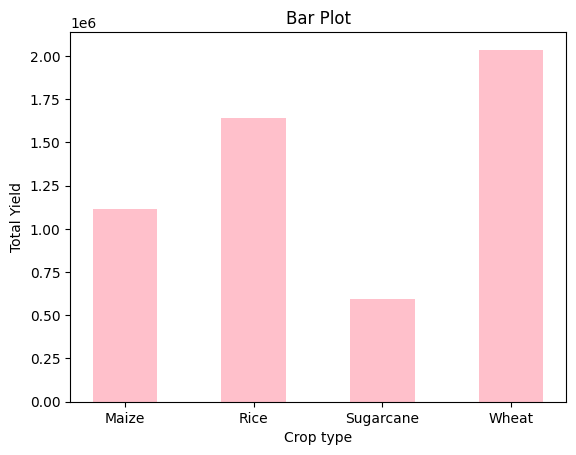

In [19]:
plt.bar(yield_by_crop.index, yield_by_crop.values, color='pink', width=0.5)
plt.xlabel('Crop type')
plt.ylabel('Total Yield')
plt.title('Bar Plot')
plt.show()

18

In [20]:
table = clean_data.pivot_table(values='YIELD_KG', index='HARVEST_DATE',
                               aggfunc='sum')
table

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
...,...
2031-03-15,1500.0
2031-03-16,2000.0
2031-03-17,2000.0


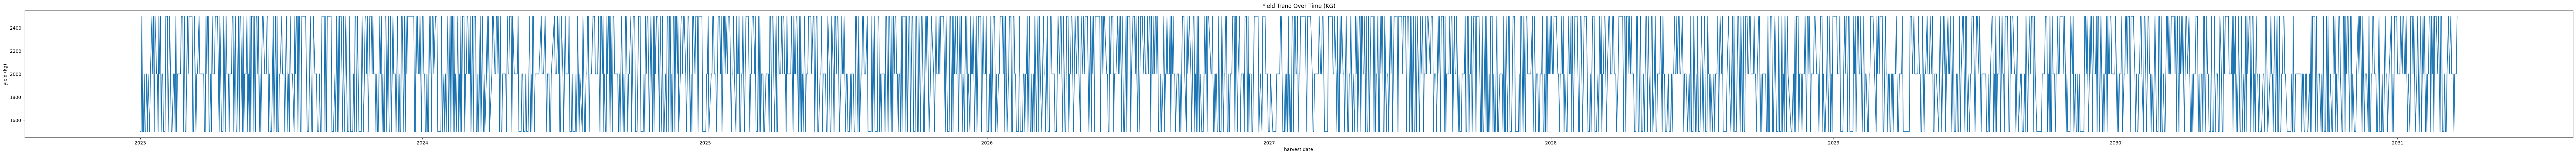

In [24]:
x = table.index
y = table.values
plt.figure(figsize=(100,5))
plt.plot(x,y)
plt.xlabel("harvest date")
plt.ylabel("yield (kg)")
plt.title("Yield Trend Over Time (KG)")
plt.show()